In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load kar rahe hain
df = pd.read_csv('train.csv')

# Pehle 5 rows dekhte hain
print("--- First 5 Rows ---")
display(df.head())

# Dataset ka structure aur total rows/columns check karte hain
print("\n--- Total Shape (Rows, Columns) ---")
print(df.shape)

Matplotlib is building the font cache; this may take a moment.


--- First 5 Rows ---


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680



--- Total Shape (Rows, Columns) ---
(9800, 18)


In [3]:
# 1. Check Missing Values (Null values)
print("--- Missing Values in Each Column ---")
print(df.isnull().sum())

# 2. Check Duplicate Rows
print("\n--- Duplicate Rows Count ---")
print(df.duplicated().sum())

# 3. Check Data Types of Columns
print("\n--- Column Data Types ---")
print(df.dtypes)

--- Missing Values in Each Column ---
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

--- Duplicate Rows Count ---
0

--- Column Data Types ---
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object


In [4]:
# 1. Postal Code ke missing values ko 0 ya mode se fill kar dete hain
df['Postal Code'] = df['Postal Code'].fillna(0)

# 2. Order Date aur Ship Date ko datetime format mein convert karna
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d/%m/%Y', errors='coerce')

# Check karte hain ki cleaning successful rahi ya nahi
print("Missing values after cleaning:")
print(df[['Postal Code', 'Order Date', 'Ship Date']].isnull().sum())

Missing values after cleaning:
Postal Code    0
Order Date     0
Ship Date      0
dtype: int64


--- Total Sales by Category ---


,Category,Sales
2,Technology,827455.8730
0,Furniture,728658.5757
1,Office Supplies,705422.3340


C:\Users\goura\AppData\Local\Temp\ipykernel_8796\1542076674.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='Sales', data=category_sales, palette='viridis')


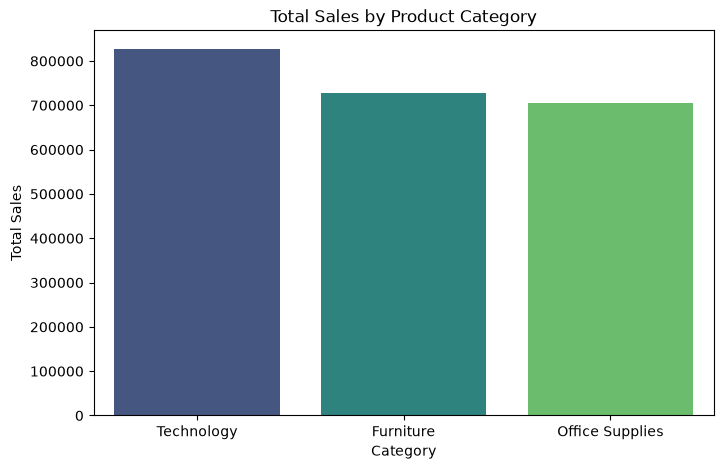

In [5]:
# 1. Category-wise Total Sales nikal rahe hain
category_sales = df.groupby('Category')['Sales'].sum().reset_index()

# Sales ko descending order (highest to lowest) mein sort karte hain
category_sales = category_sales.sort_values(by='Sales', ascending=False)

print("--- Total Sales by Category ---")
display(category_sales)

# 2. Iska ek bar chart banate hain (Visualization)
plt.figure(figsize=(8, 5))
sns.barplot(x='Category', y='Sales', data=category_sales, palette='viridis')
plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

--- Top 5 States by Sales ---


,State,Sales
3,California,446306.4635
30,New York,306361.1470
41,Texas,168572.5322
45,Washington,135206.8500
36,Pennsylvania,116276.6500


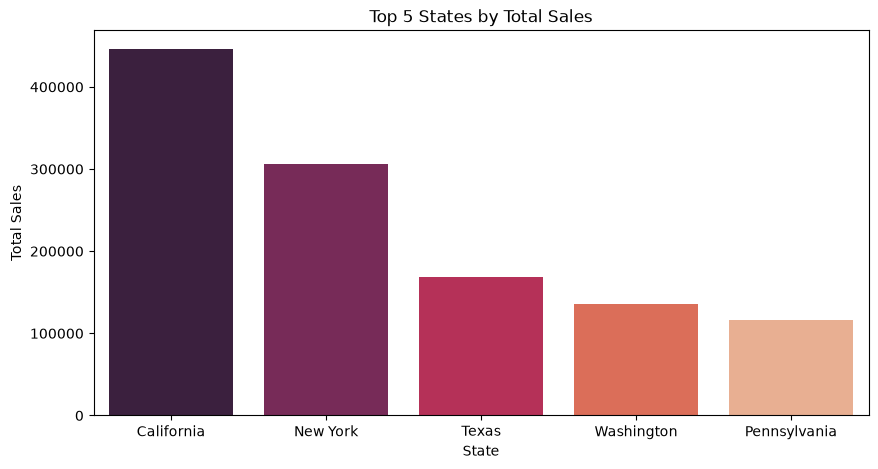

In [6]:
# State-wise total sales nikal kar top 5 states select kar rahe hain
state_sales = df.groupby('State')['Sales'].sum().reset_index()
state_sales = state_sales.sort_values(by='Sales', ascending=False).head(5)

print("--- Top 5 States by Sales ---")
display(state_sales)

# Iska bar chart banate hain
plt.figure(figsize=(10, 5))
sns.barplot(x='State', y='Sales', data=state_sales, hue='State', palette='magica' if 'magica' in sns.color_palette() else 'rocket', legend=False)
plt.title('Top 5 States by Total Sales')
plt.xlabel('State')
plt.ylabel('Total Sales')
plt.show()

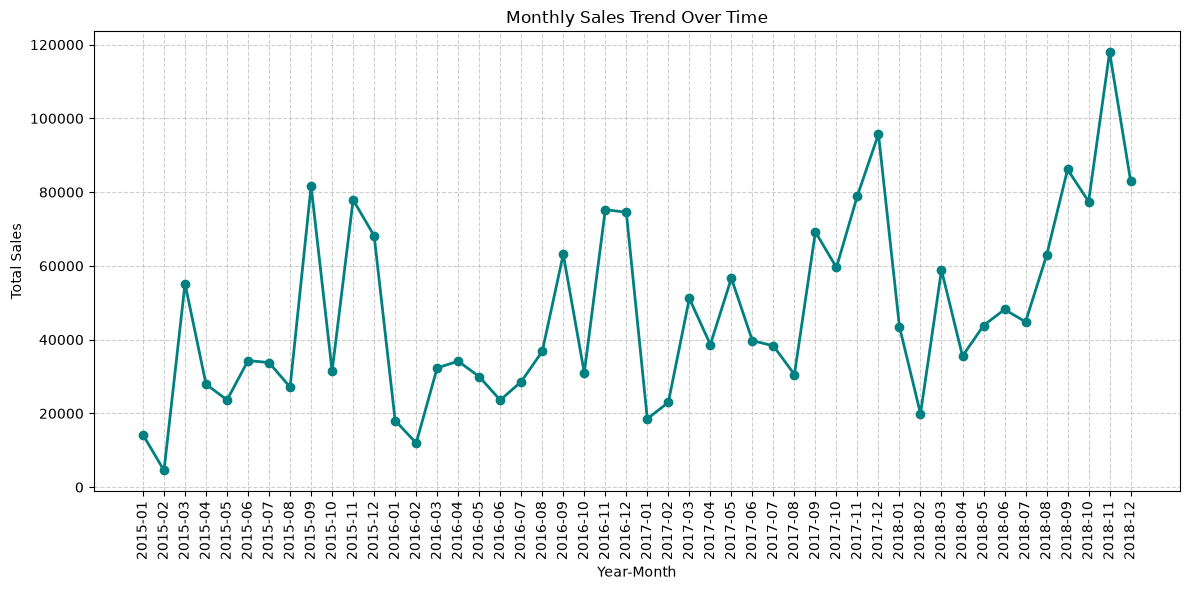

In [7]:
# Order Date se Year aur Month nikal kar monthly sales trend banate hain
df['Month_Year'] = df['Order Date'].dt.to_period('M')
monthly_sales = df.groupby('Month_Year')['Sales'].sum().reset_index()
monthly_sales['Month_Year'] = monthly_sales['Month_Year'].astype(str)

# Line chart banate hain sales trend ke liye
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales['Month_Year'], monthly_sales['Sales'], marker='o', color='teal', linewidth=2)
plt.title('Monthly Sales Trend Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

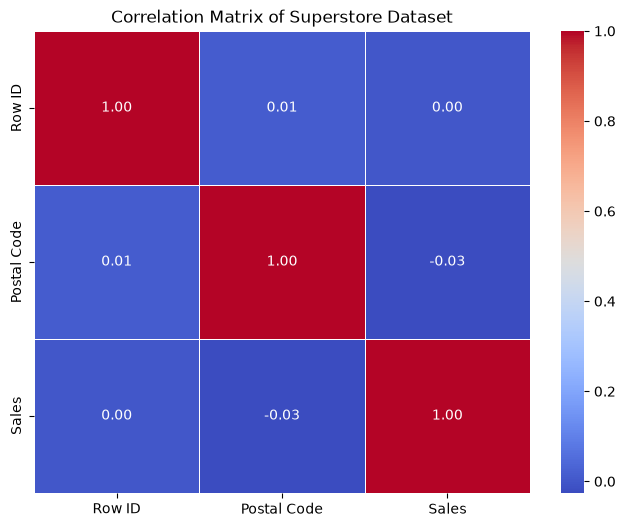

In [8]:
# Correlation matrix sirf numeric columns ke liye
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Superstore Dataset')
plt.show()